In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os

In [5]:
data_path = Path("../data/mart")

In [6]:
data = pd.read_csv(data_path / "data.csv")

In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1097 entries, 0 to 1096
Data columns (total 39 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   date                1097 non-null   str    
 1   market_me           1097 non-null   float64
 2   market_mtb          1097 non-null   float64
 3   market_volume       1097 non-null   float64
 4   nout_volume         1097 non-null   float64
 5   oil                 1097 non-null   float64
 6   gold                1097 non-null   float64
 7   exchange            1097 non-null   float64
 8   rsi                 1097 non-null   float64
 9   pli                 1097 non-null   float64
 10  i                   1097 non-null   float64
 11  return_wholesale    1097 non-null   float64
 12  return_groce        1097 non-null   float64
 13  return_retail       1097 non-null   float64
 14  return_petro        1097 non-null   float64
 15  return_service      1097 non-null   float64
 16  return_hospitalit

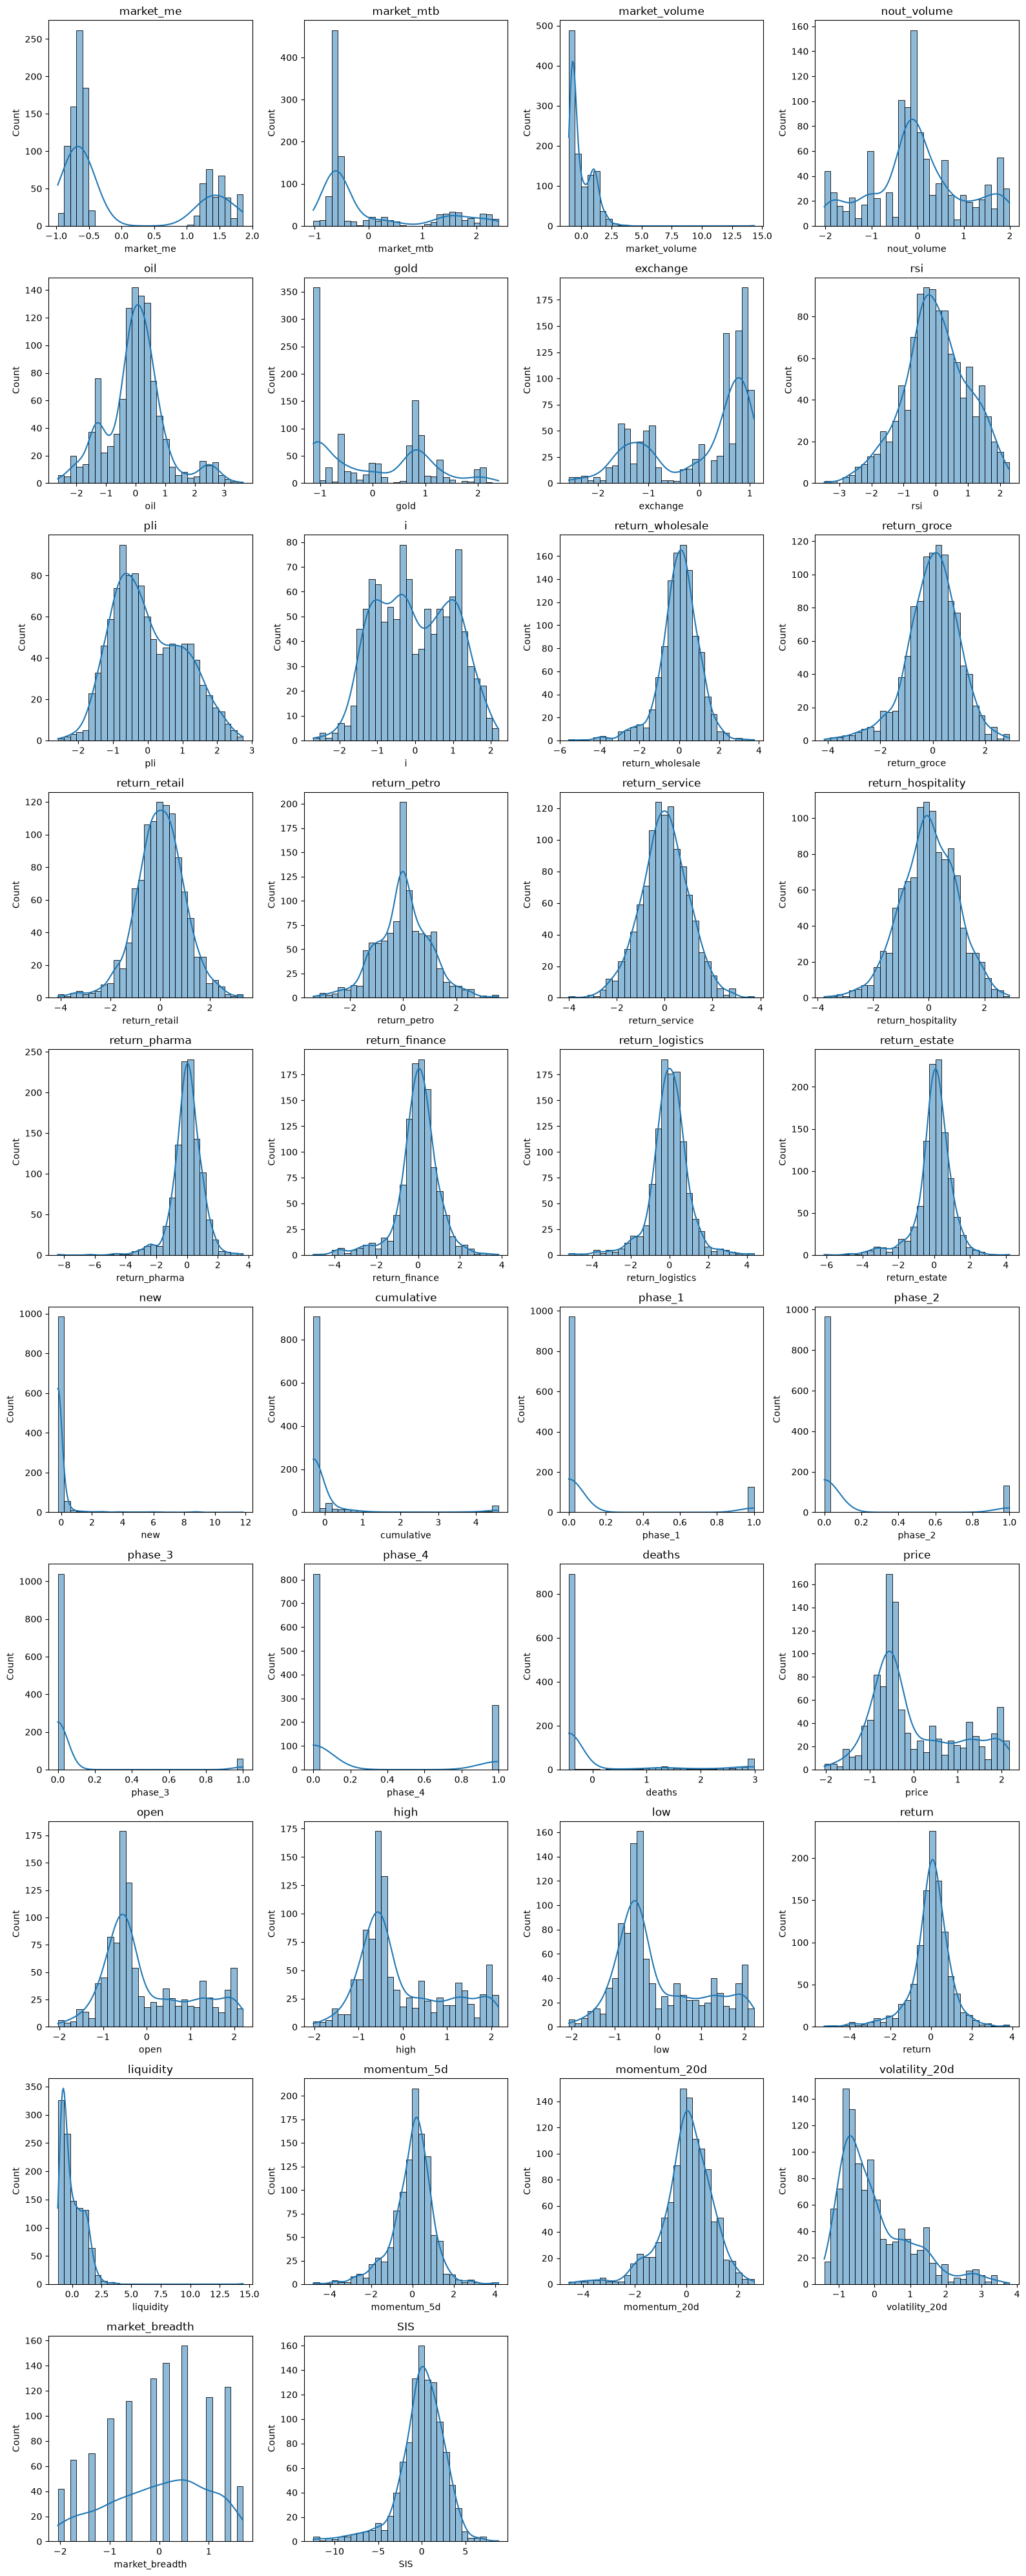

In [7]:
numeric_data = data.select_dtypes(include=np.number)

n_cols = 4
n_rows = int(np.ceil(len(numeric_data.columns) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = np.atleast_1d(axes).ravel()

for ax, column in zip(axes, numeric_data.columns):
    sns.histplot(numeric_data[column].dropna(), bins=30, kde=True, ax=ax)
    ax.set_title(column)

for ax in axes[len(numeric_data.columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

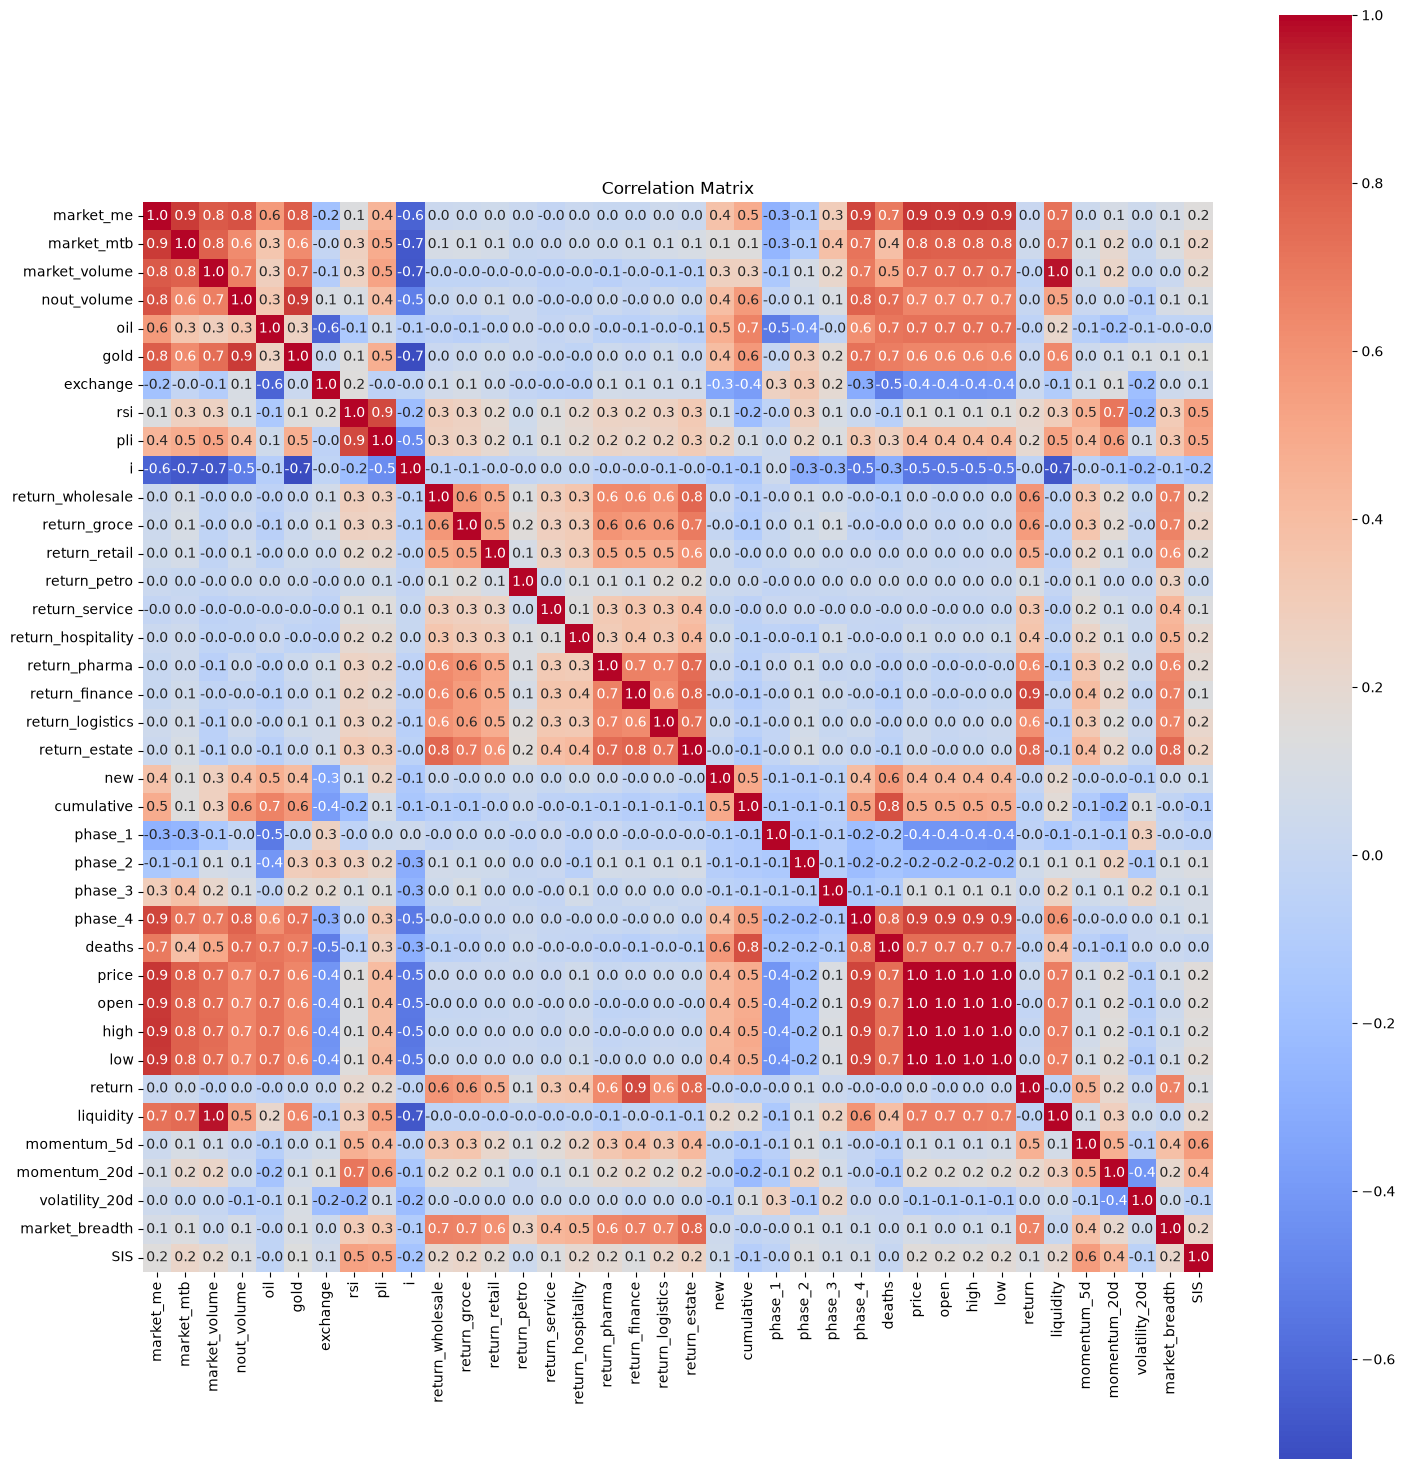

In [16]:
correlation_matrix = numeric_data.corr()

plt.figure(figsize=(15, 15))
sns.heatmap(correlation_matrix, annot=True, fmt=".1f", cmap="coolwarm", cbar=True, square=True)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

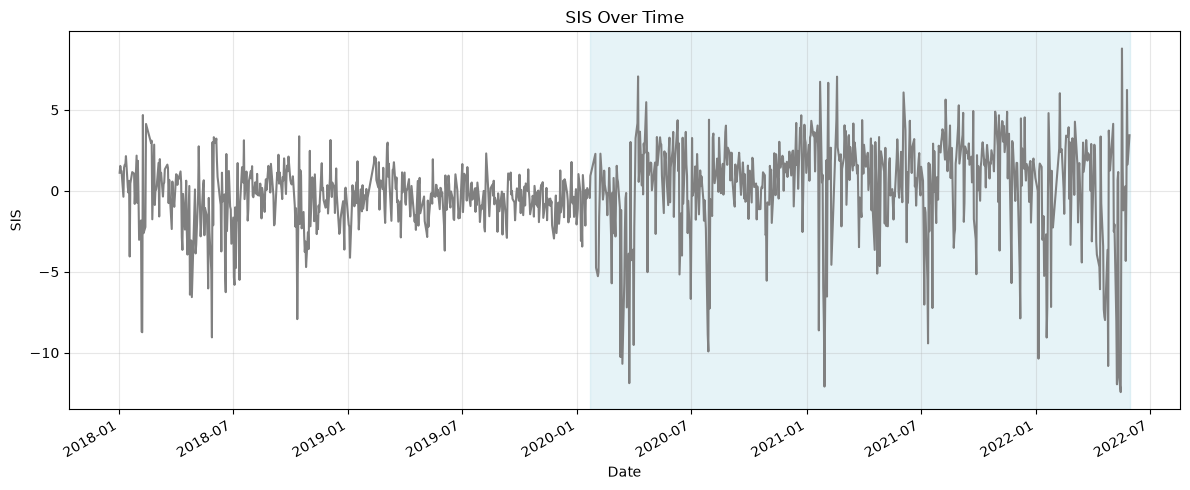

In [26]:
dates = pd.to_datetime(data["date"])

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(dates, data["SIS"], linewidth=1.5, color="grey")
start_date = pd.Timestamp("2020-01-22")
ax.axvspan(start_date, dates.max(), color="lightblue", alpha=0.3)
ax.set(title="SIS Over Time", xlabel="Date", ylabel="SIS")
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

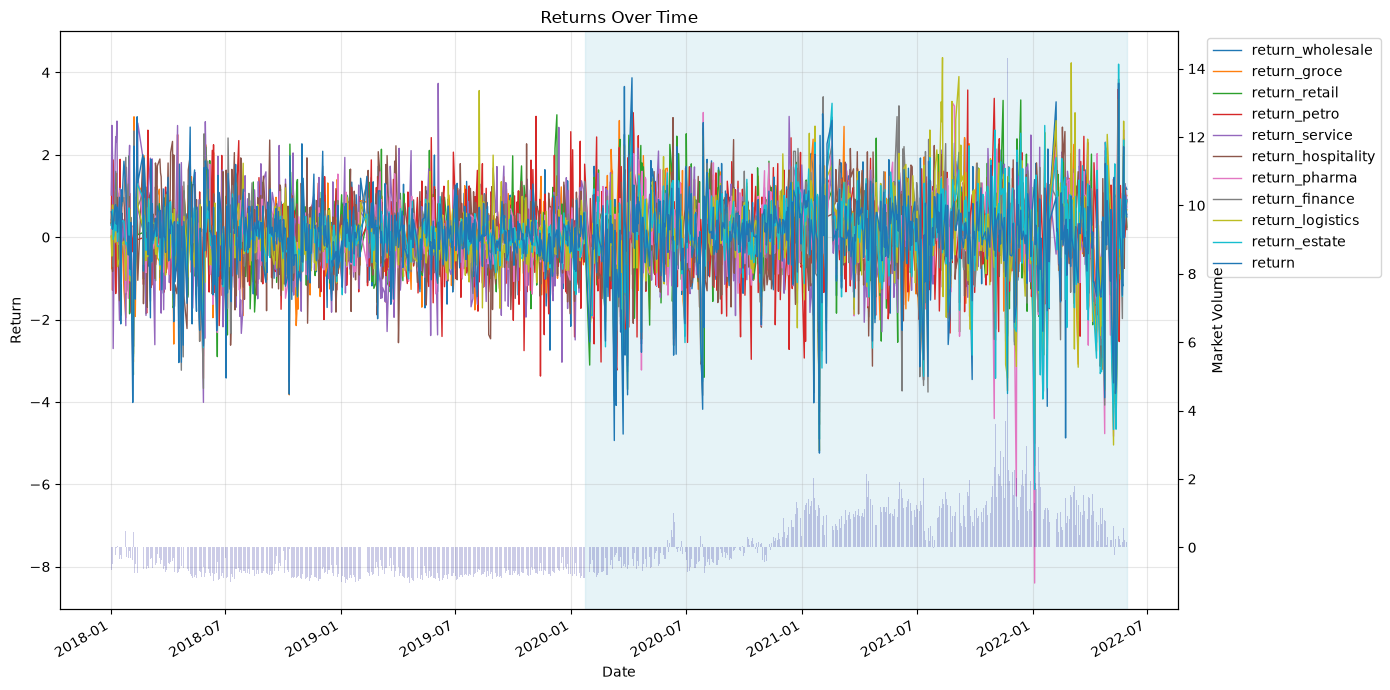

In [30]:
return_columns = [col for col in data.columns if col == "return" or col.startswith("return_")]

fig, ax = plt.subplots(figsize=(14, 7))
for column in return_columns:
    ax.plot(dates, data[column], label=column, linewidth=1)

ax.set(title="Returns Over Time", xlabel="Date", ylabel="Return")
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax2 = ax.twinx()
ax2.bar(dates, data["market_volume"], width=1, color="darkblue", alpha=0.2)
ax2.set_ylabel("Market Volume")
start_date = pd.Timestamp("2020-01-22")
ax.axvspan(start_date, dates.max(), color="lightblue", alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [32]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss

alpha = 0.05
stationarity_rows = []

for name in data.select_dtypes(include=np.number).columns:
    series = data[name].replace([np.inf, -np.inf], np.nan).dropna()

    if len(series) < 10 or series.nunique() < 2:
        stationarity_rows.append({
            "variable": name,
            "n": len(series),
            "ADF statistic": np.nan,
            "ADF p-value": np.nan,
            "KPSS statistic": np.nan,
            "KPSS p-value": np.nan,
            "conclusion": "Insufficient variation or observations",
        })
        continue

    try:
        adf_stat, adf_p, *_ = adfuller(series, regression="c", autolag="AIC")
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            kpss_stat, kpss_p, *_ = kpss(series, regression="c", nlags="auto")

        if adf_p < alpha and kpss_p >= alpha:
            conclusion = "Stationary"
        elif adf_p >= alpha and kpss_p < alpha:
            conclusion = "Non-stationary"
        else:
            conclusion = "Inconclusive (tests disagree or both fail to reject)"

        stationarity_rows.append({
            "variable": name,
            "n": len(series),
            "ADF statistic": adf_stat,
            "ADF p-value": adf_p,
            "KPSS statistic": kpss_stat,
            "KPSS p-value": kpss_p,
            "conclusion": conclusion,
        })
    except Exception as exc:
        stationarity_rows.append({
            "variable": name,
            "n": len(series),
            "ADF statistic": np.nan,
            "ADF p-value": np.nan,
            "KPSS statistic": np.nan,
            "KPSS p-value": np.nan,
            "conclusion": f"Test failed: {exc}",
        })

stationarity_results = pd.DataFrame(stationarity_rows).set_index("variable")
stationarity_results

C:\Users\tangc\AppData\Local\Temp\ipykernel_10332\1508868164.py:23: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, *_ = adfuller(series, regression="c", autolag="AIC")
C:\Users\tangc\AppData\Local\Temp\ipykernel_10332\1508868164.py:23: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, *_ = adfuller(series, regression="c", autolag="AIC")
C:\Use

,n,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value,conclusion
variable,,,,,,
market_me,1097,-0.375225,9.141538e-01,3.977429,0.010000,Non-stationary
market_mtb,1097,-1.450737,5.577253e-01,2.994873,0.010000,Non-stationary
market_volume,1097,-1.916443,3.243659e-01,4.255168,0.010000,Non-stationary
nout_volume,1097,-0.375191,9.141593e-01,4.817722,0.010000,Non-stationary
oil,1097,-0.390518,9.116699e-01,1.123857,0.010000,Non-stationary
gold,1097,0.772197,9.911739e-01,5.050393,0.010000,Non-stationary
exchange,1097,-1.650066,4.570059e-01,1.220464,0.010000,Non-stationary
rsi,1097,-4.856158,4.241562e-05,0.434796,0.062157,Stationary
pli,1097,-3.616751,5.448745e-03,1.882024,0.010000,Inconclusive (tests disagree or both fail to r...
